# White House Visitor Logs: Access Patterns for Security Analysts

**Question:** when and where do visitors access the White House complex, and what patterns should security staff plan around?

**Audience and purpose:** security analysts reviewing access control and facility use, to decide where and when staffing should be increased and what needs a closer look.

**Data:** five public White House visitor access record (WAVES) files: all of 2021, then June and December of 2022 and 2023. Together they hold 362,847 rows with 38 columns after the two different column layouts are matched up.

**Approach:** combine the files under one set of column names, remove duplicates, parse the arrival time in both of the date formats the files use, give each person a pseudonymous visitor ID, then chart frequent visitors, meeting rooms, locations over time, monthly volume, time of day and daily volume, follow the most frequent visitors month by month, and build a flag table for review.

**Key results:**
- 255,092 access events with a recorded arrival time, from January 20, 2021 to December 31, 2023.
- The East Wing tour is by far the busiest destination (124,154 events), and 82% of events are in the White House itself.
- Volume grows sharply over the period: December 2021 had 10,856 events, December 2023 had 93,757. The busiest single day was December 23, 2023 (6,846).
- 91.5% of arrivals fall between 8 a.m. and 8 p.m., and 83.3% of visitors came only once.
- A flag table marks 2,147 visitors (1.1%) for review; 295 of them are frequent, spread over many months and many different days.

**Tools:** Python (pandas, matplotlib, seaborn)

**Context:** master's coursework (DSC640, Weeks 3 and 4), cleaned up and corrected for this portfolio.

## 1. Load and combine the five files

In [1]:
# import the required libraries
import warnings
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import seaborn as sns

warnings.filterwarnings('ignore', category=FutureWarning)
sns.set_theme(style='white')
output_dir = Path('wh_visit_visualizations'); output_dir.mkdir(exist_ok=True)

In [2]:
files = ['2021_WAVES-ACCESS-RECORDS White House.csv', '2022.06_WAVES-ACCESS-RECORDS.csv', '2022.12_WAVES-ACCESS-RECORDS.csv',
         '2023.06_WAVES-ACCESS-RECORDS.csv', '2023.12_WAVES-ACCESS-RECORDS.csv']

# the 2021 file uses older column names (NAMELAST, MEETING_LOC, ...); map both layouts to one set of names
rename_map = {'namelast': 'last_name', 'namefirst': 'first_name', 'meeting_loc': 'meeting_location',
              'visitee_namelast': 'visitee_last_name', 'visitee_namefirst': 'visitee_first_name'}
frames = []
for f in files:
    d = pd.read_csv(f, low_memory=False)
    d.columns = [c.strip().lower().replace(' ', '_') for c in d.columns]
    d = d.rename(columns=rename_map)
    d = d.loc[:, ~d.columns.duplicated()]          # a few files repeat a column name
    d['source_file'] = f
    frames.append(d)
    print(f'{f}: {len(d):,} rows')
df = pd.concat(frames, ignore_index=True, sort=False)
print(f'Combined: {df.shape[0]:,} rows, {df.shape[1]} columns')

2021_WAVES-ACCESS-RECORDS White House.csv: 41,412 rows
2022.06_WAVES-ACCESS-RECORDS.csv: 17,400 rows


2022.12_WAVES-ACCESS-RECORDS.csv: 87,061 rows


2023.06_WAVES-ACCESS-RECORDS.csv: 94,836 rows


2023.12_WAVES-ACCESS-RECORDS.csv: 122,138 rows
Combined: 362,847 rows, 38 columns


## 2. Clean

In [3]:
before = len(df)
df = df.drop_duplicates()
print(f'Exact duplicate rows removed: {before - len(df):,}')

# time of arrival (TOA) is the access timestamp; rows without one cannot be placed in time
# the files use two formats ('12/17/2021 12:23' and 'Jun 16 2022  2:13PM'), so each value is parsed on its own
missing_in_source = df['toa'].isna().sum()
df['toa'] = pd.to_datetime(df['toa'], errors='coerce', format='mixed')
print(f'Blank in the source files: {missing_in_source:,}   Could not be read as a date: {df["toa"].isna().sum() - missing_in_source:,}')
print(f"Rows with no time of arrival: {df['toa'].isna().sum():,} ({df['toa'].isna().mean():.1%})")
df = df[df['toa'].notna()].copy()
df['date'] = df['toa'].dt.normalize()
df['month_year'] = df['toa'].dt.to_period('M')
df['hour'] = df['toa'].dt.hour
for col in ['meeting_location', 'meeting_room']:
    df[col] = df[col].astype(str).str.strip().replace({'nan': pd.NA, '': pd.NA})
print(f"Access events kept: {len(df):,}, from {df['toa'].min():%b %d, %Y} to {df['toa'].max():%b %d, %Y}")

Exact duplicate rows removed: 300


Blank in the source files: 107,455   Could not be read as a date: 0
Rows with no time of arrival: 107,455 (29.6%)


Access events kept: 255,092, from Jan 20, 2021 to Dec 31, 2023


## 3. Pseudonymous visitor IDs
Each person gets a stable code (for example `V-000421`) so their visits can be followed over time without showing their name. Names are matched after trimming spaces and ignoring capitalization. Codes are numbered in order of each person's first recorded visit, so they cannot be turned back into names without the lookup table, which is saved to `private/visitor_id_lookup.csv` for authorized follow-up and is not part of the published charts.

Limits: the data has no true visitor ID (the UIN field identifies the appointment, not the person), so two different people with the same name share a code, and one person whose name is spelled differently across files gets two codes.

In [4]:
named = df['last_name'].notna() & df['first_name'].notna()
df['visitor_key'] = (df['last_name'].astype(str).str.strip().str.upper() + '|' +
                     df['first_name'].astype(str).str.strip().str.upper()).where(named)

# number each person in order of their first visit (ties broken by name), so the codes do not depend on file order
first_seen = df[named].groupby('visitor_key')['toa'].min().reset_index().sort_values(['toa', 'visitor_key'])
first_seen['visitor_id'] = [f'V-{i:06d}' for i in range(1, len(first_seen) + 1)]
df = df.merge(first_seen[['visitor_key', 'visitor_id']], on='visitor_key', how='left')

Path('private').mkdir(exist_ok=True)
first_seen[['visitor_id', 'visitor_key']].to_csv('private/visitor_id_lookup.csv', index=False)
print(f"Access events with a visitor name: {named.sum():,} of {len(df):,}   People (visitor IDs): {len(first_seen):,}")

Access events with a visitor name: 255,086 of 255,092   People (visitor IDs): 195,121


## 4. Visualizations
Audience: security analysts looking for patterns and risks in building access. Charts identify people only by their visitor ID (the original write-up recommended anonymizing names before public release).

Visitor IDs: 195,121   Visited once: 83.3%   5+ access events: 3,298   Most by one person: 61
visitor_id
V-003429    61
V-000123    34
V-000374    34
V-001697    33
V-003176    30
V-000094    30
V-008794    27
V-000830    27
V-000923    27
V-003618    26


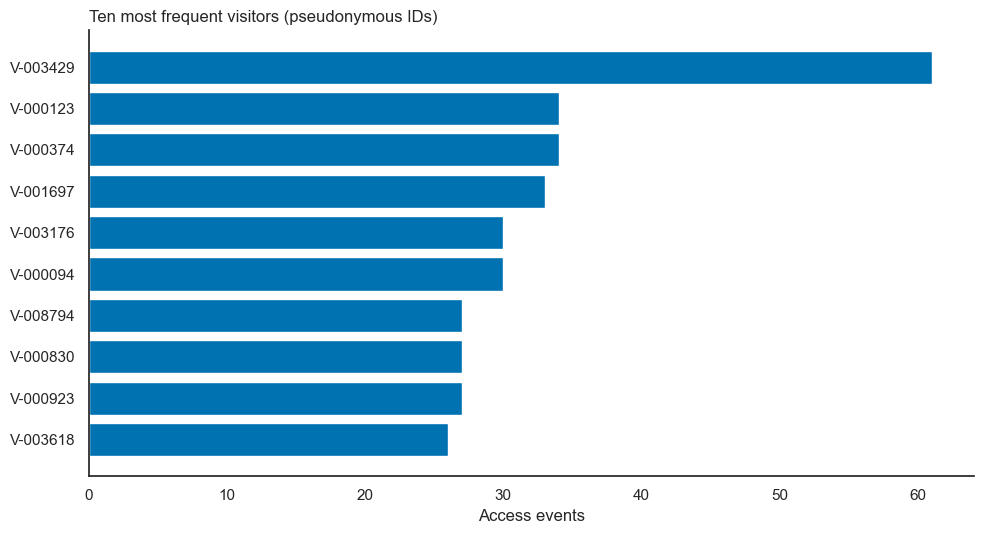

In [5]:
# Visual 1: how often individual visitors return
visits_per_person = df.dropna(subset=['visitor_id']).groupby('visitor_id').size()
print(f'Visitor IDs: {len(visits_per_person):,}   Visited once: {(visits_per_person == 1).mean():.1%}   '
      f'5+ access events: {(visits_per_person >= 5).sum():,}   Most by one person: {visits_per_person.max()}')
top10 = visits_per_person.sort_values(ascending=False).head(10)
print(top10.to_string())

fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top10.index[::-1], top10.values[::-1], color='#0072B2')
ax.set_title('Ten most frequent visitors (pseudonymous IDs)', loc='left'); ax.set_xlabel('Access events')
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(output_dir / 'vis1_top10_visitors_anonymized.png', dpi=200); plt.show()

meeting_room
EW TOUR                 124154
EW - RES                 34092
WEST WING                 9079
Res-State Floor           8422
SOUTH LAWN                6285
1st Floor VPR/Poolsi      3659
EW 216                    3041
BOWLING ALLEY - 037       2798
350                       2706
374                       1742


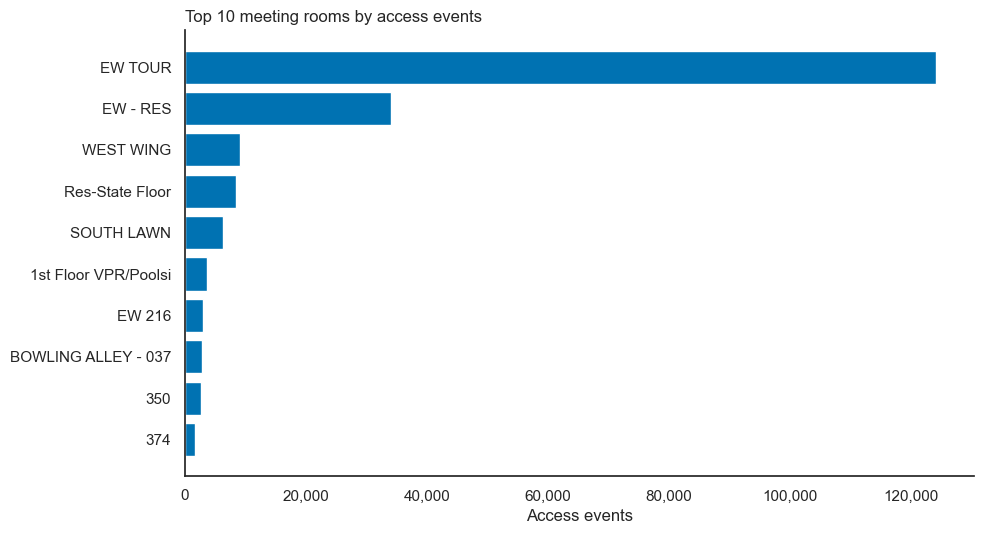

In [6]:
# Visual 2: most-used meeting rooms
top_rooms = df['meeting_room'].dropna().value_counts().head(10)
print(top_rooms.to_string())
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.barh(top_rooms.index[::-1], top_rooms.values[::-1], color='#0072B2')
ax.set_title('Top 10 meeting rooms by access events', loc='left'); ax.set_xlabel('Access events')
ax.xaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}')); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(output_dir / 'vis2_top10_rooms_bar.png', dpi=200); plt.show()

Access events by location (all months):
location_group
WH      209291
OEOB     33659
VPR       9300
NEOB      2369
EEOB       473


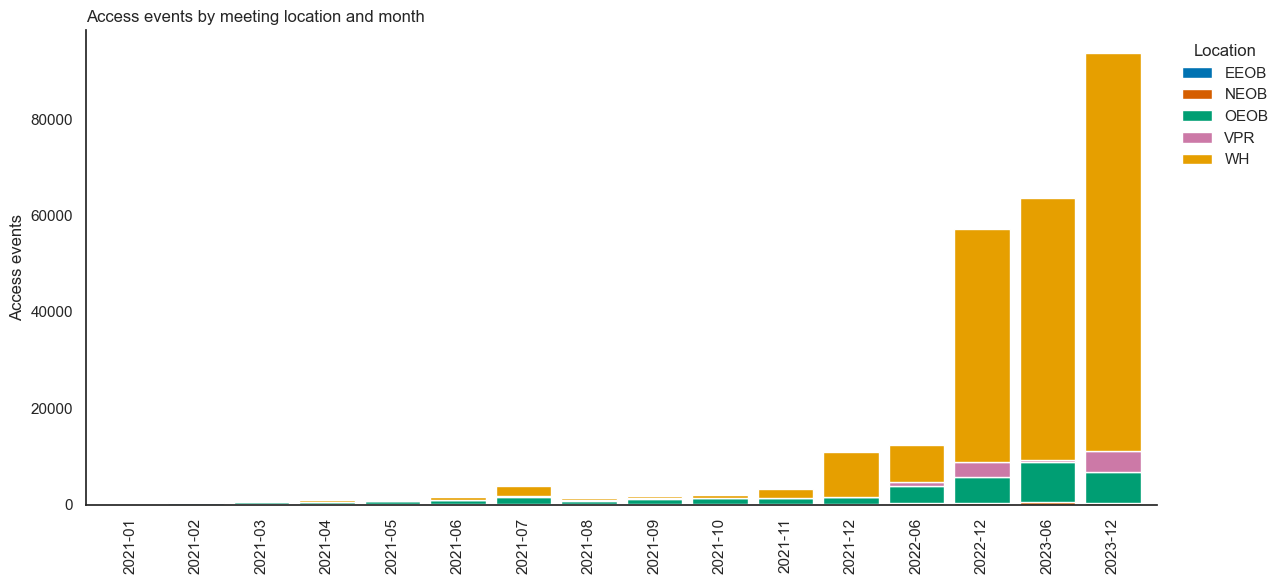

In [7]:
# Visual 3: stacked bars over time by meeting location (top 5 locations, the rest grouped as Other)
top_locs = df['meeting_location'].value_counts().head(5).index
df['location_group'] = df['meeting_location'].where(df['meeting_location'].isin(top_locs), 'Other / not recorded')
loc_by_month = df.groupby(['month_year', 'location_group']).size().unstack(fill_value=0)
print('Access events by location (all months):'); print(loc_by_month.sum().sort_values(ascending=False).to_string())
ax = loc_by_month.plot(kind='bar', stacked=True, figsize=(13, 6), width=0.85,
                       color=['#0072B2', '#D55E00', '#009E73', '#CC79A7', '#E69F00', '#999999'])
ax.set_title('Access events by meeting location and month', loc='left'); ax.set_xlabel(''); ax.set_ylabel('Access events')
ax.legend(title='Location', bbox_to_anchor=(1.01, 1), loc='upper left', frameon=False)
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(output_dir / 'vis3_meeting_loc_stacked_bar.png', dpi=200); plt.show()

Months with data: 16   Busiest: 2023-12 (93,757)   Quietest: 2021-01 (183)
month_year
2021-01      183
2021-02      603
2021-03      726
2021-04      926
2021-05     1030
2021-06     1529
2021-07     3789
2021-08     1408
2021-09     1784
2021-10     1984
2021-11     3232
2021-12    10856
2022-06    12488
2022-12    57233
2023-06    63564
2023-12    93757
Freq: M


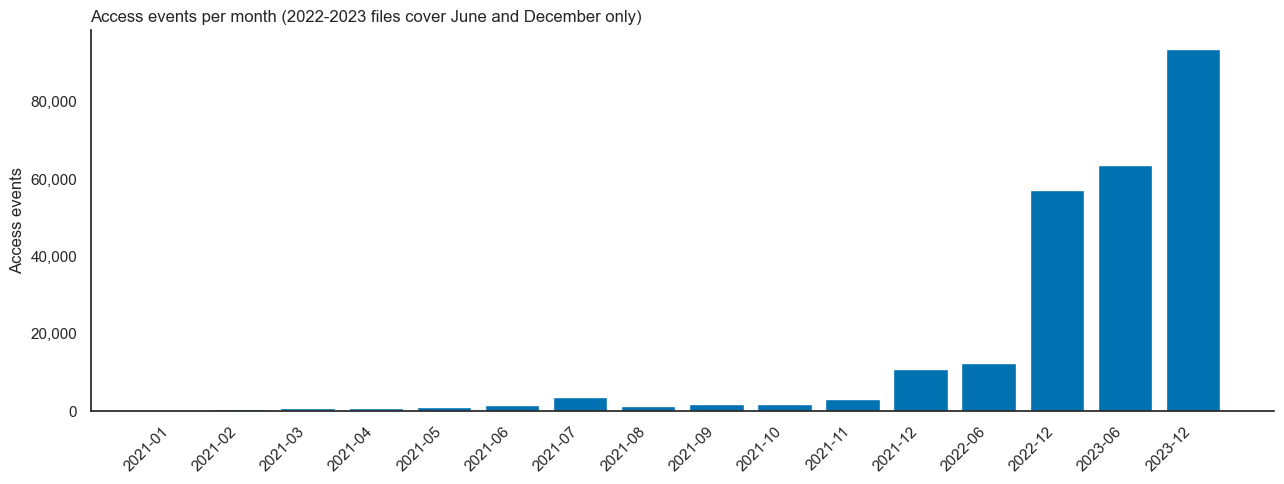

In [8]:
# Visual 4: monthly access events
monthly = df.groupby('month_year').size()
print(f'Months with data: {len(monthly)}   Busiest: {monthly.idxmax()} ({monthly.max():,})   Quietest: {monthly.idxmin()} ({monthly.min():,})')
print(monthly.to_string())
# after 2021 the files only cover June and December, so bars are used rather than a line that would imply missing months
fig, ax = plt.subplots(figsize=(13, 5))
ax.bar(monthly.index.astype(str), monthly.values, color='#0072B2')
ax.set_title('Access events per month (2022-2023 files cover June and December only)', loc='left'); ax.set_ylabel('Access events')
plt.xticks(rotation=45, ha='right')
ax.yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}')); ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(output_dir / 'vis4_visits_monthly_line.png', dpi=200); plt.show()

Share of access events between 8 a.m. and 8 p.m.: 91.5%   Busiest hour: 10:00


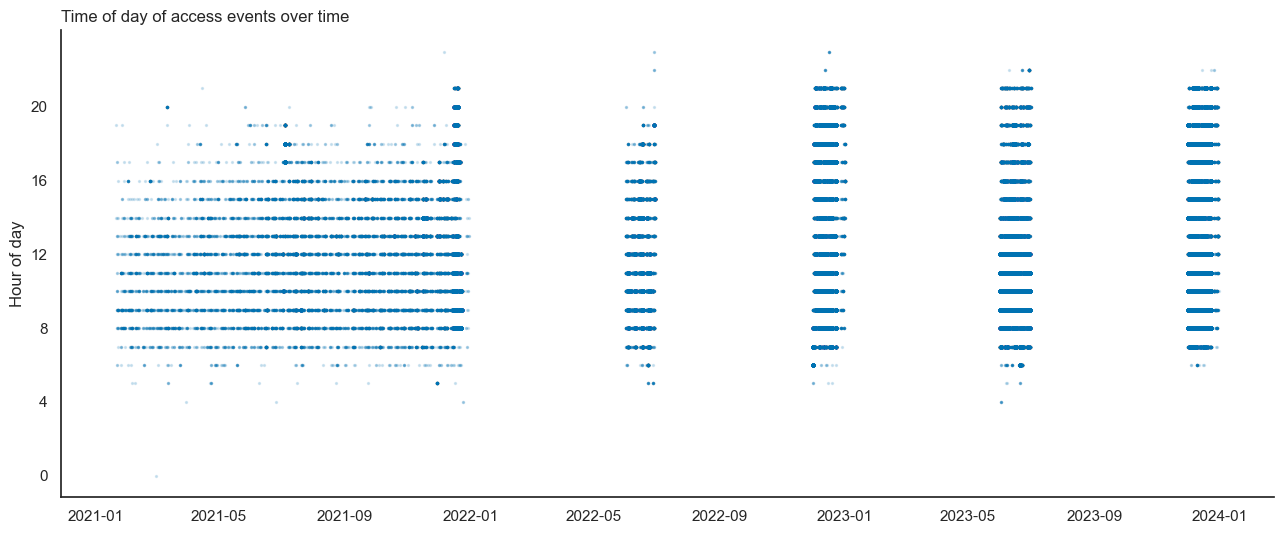

In [9]:
# Visual 5: time of day of each access event over time
share_8_to_8 = df['hour'].between(8, 19).mean()
print(f'Share of access events between 8 a.m. and 8 p.m.: {share_8_to_8:.1%}   Busiest hour: {df["hour"].mode()[0]}:00')
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.scatter(df['toa'], df['hour'], s=2, alpha=0.15, color='#0072B2')
ax.set_title('Time of day of access events over time', loc='left'); ax.set_ylabel('Hour of day'); ax.set_yticks(range(0, 24, 4))
ax.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(output_dir / 'vis5_hourly_arrivals_scatter.png', dpi=200); plt.show()

Days in the covered months: 487   Days with any access events: 435   Median per day: 50   Busiest day: Dec 23, 2023 (6,846)


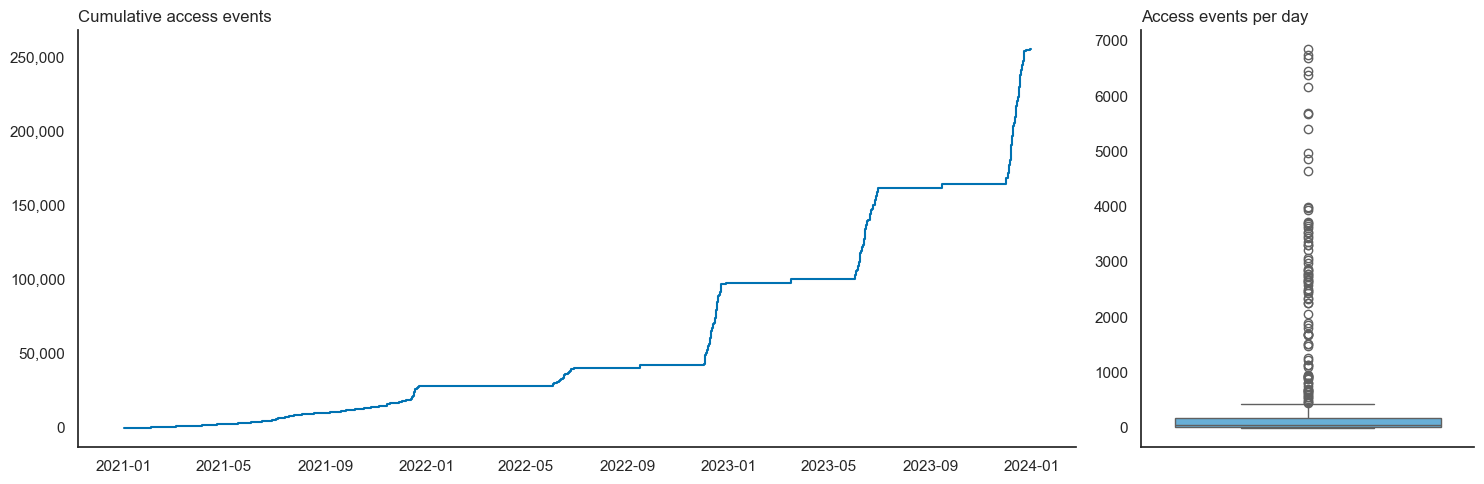

In [10]:
# Visual 6: cumulative access events (step chart) and Visual 7: distribution of daily counts
# only count days inside the months the files cover, so the gaps between files are not treated as zero-visit days
daily = df.groupby('date').size()
covered_days = pd.DatetimeIndex([d for m in monthly.index for d in pd.date_range(m.start_time, m.end_time.normalize(), freq='D')])
daily_full = daily.reindex(covered_days, fill_value=0)
print(f'Days in the covered months: {len(covered_days):,}   Days with any access events: {(daily_full > 0).sum():,}   '
      f'Median per day: {daily_full.median():,.0f}   Busiest day: {daily_full.idxmax():%b %d, %Y} ({daily_full.max():,})')

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={'width_ratios': [3, 1]})
axes[0].step(daily_full.index, daily_full.cumsum(), where='mid', color='#0072B2')
axes[0].set_title('Cumulative access events', loc='left'); axes[0].yaxis.set_major_formatter(ticker.StrMethodFormatter('{x:,.0f}'))
sns.boxplot(y=daily_full.values, ax=axes[1], color='#56B4E9')
axes[1].set_title('Access events per day', loc='left')
for a in axes: a.spines[['top', 'right']].set_visible(False)
plt.tight_layout(); plt.savefig(output_dir / 'vis6_7_cumulative_and_daily.png', dpi=200); plt.show()

## 5. Repeat visitors over time
Each row is one of the 15 most frequent visitors; each column is a month in the data. This shows whether a person's visits are spread out or bunched into a single event.

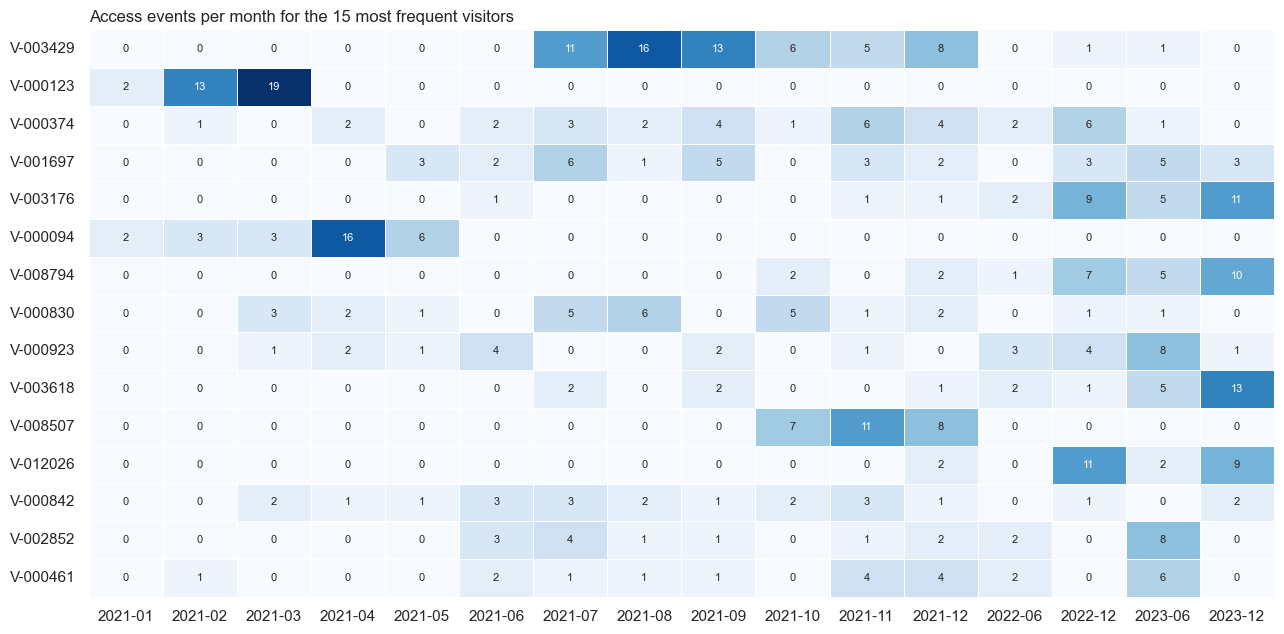

Months with at least one access event, per top-15 visitor:
visitor_id
V-003429     8
V-000123     3
V-000374    12
V-001697    10
V-003176     7
V-000094     5
V-008794     6
V-000830    10
V-000923    10
V-003618     7
V-008507     3
V-012026     4
V-000842    12
V-002852     8
V-000461     9


In [11]:
top15 = visits_per_person.sort_values(ascending=False).head(15).index
trend = (df[df['visitor_id'].isin(top15)].groupby(['visitor_id', 'month_year']).size()
         .unstack(fill_value=0).reindex(columns=monthly.index, fill_value=0).loc[top15])
trend.columns = trend.columns.astype(str)
fig, ax = plt.subplots(figsize=(13, 6.5))
sns.heatmap(trend, cmap='Blues', annot=True, fmt='d', cbar=False, linewidths=0.5, linecolor='white', ax=ax, annot_kws={'fontsize': 8})
ax.set_title('Access events per month for the 15 most frequent visitors', loc='left'); ax.set_xlabel(''); ax.set_ylabel('')
plt.tight_layout(); plt.savefig(output_dir / 'vis8_top_visitors_by_month.png', dpi=200); plt.show()
print('Months with at least one access event, per top-15 visitor:')
print((trend > 0).sum(axis=1).to_string())

## 6. Flag table for review
Each visitor is checked against four rules. A flag is a reason to look closer, not a finding of wrongdoing; most flagged visitors will have ordinary explanations (staff guests, recurring meetings, event volunteers).

| Rule | Flagged when |
|---|---|
| High frequency | 10 or more access events |
| Spread over time | access events in 4 or more of the 16 months in the data |
| Off hours | 3 or more arrivals before 6 a.m. or after 10 p.m. |
| Many days | arrivals on 10 or more different days |

In [12]:
v = df.dropna(subset=['visitor_id'])
per = v.groupby('visitor_id').agg(
    access_events=('toa', 'size'),
    days=('date', 'nunique'),
    months=('month_year', 'nunique'),
    off_hours=('hour', lambda h: int(((h < 6) | (h >= 22)).sum())),
    first_seen=('toa', 'min'),
    last_seen=('toa', 'max'),
    top_room=('meeting_room', lambda r: r.mode().iloc[0] if r.notna().any() else ''),
)
rules = {'flag_high_frequency': per['access_events'] >= 10, 'flag_spread_over_time': per['months'] >= 4,
         'flag_off_hours': per['off_hours'] >= 3, 'flag_many_days': per['days'] >= 10}
for name, mask in rules.items():
    per[name] = mask
per['flags'] = sum(rules.values())
flagged = per[per['flags'] > 0].sort_values(['flags', 'access_events'], ascending=False)

print('Visitors flagged by each rule:')
for name, mask in rules.items():
    print(f'  {name:23s} {mask.sum():>5,}')
print(f'Visitors with at least one flag: {len(flagged):,} of {len(per):,} ({len(flagged) / len(per):.2%})')
print('Visitors by number of flags:', flagged['flags'].value_counts().sort_index(ascending=False).to_dict())

flagged.to_csv('wh_visitor_flags.csv', date_format='%Y-%m-%d %H:%M')
cols = ['flags', 'access_events', 'days', 'months', 'off_hours', 'first_seen', 'last_seen', 'top_room']
flagged[cols].head(25).assign(first_seen=lambda t: t['first_seen'].dt.strftime('%Y-%m-%d'),
                              last_seen=lambda t: t['last_seen'].dt.strftime('%Y-%m-%d'))

Visitors flagged by each rule:
  flag_high_frequency       408
  flag_spread_over_time   2,080
  flag_off_hours              1
  flag_many_days            332
Visitors with at least one flag: 2,147 of 195,121 (1.10%)
Visitors by number of flags: {3: 295, 2: 84, 1: 1768}


,flags,access_events,days,months,off_hours,first_seen,last_seen,top_room
visitor_id,,,,,,,,
V-003429,3,61,61,8,0,2021-07-01,2023-06-17,RESIDENCE
V-000374,3,34,32,12,0,2021-02-15,2023-06-12,WW 132
V-001697,3,33,30,10,0,2021-05-07,2023-12-18,WW Lobby
V-000094,3,30,27,5,0,2021-01-26,2021-05-07,234
V-003176,3,30,27,7,0,2021-06-24,2023-12-21,EW TOUR
V-000830,3,27,27,10,0,2021-03-19,2023-06-27,374
V-000923,3,27,27,10,0,2021-03-29,2023-12-01,374
V-008794,3,27,22,6,0,2021-10-12,2023-12-26,374
V-003618,3,26,22,7,0,2021-07-02,2023-12-19,1st Floor VPR/Poolsi


## Findings and recommendations
- **Most traffic is tours and the residence.** The East Wing tour (124,154 events) and East Wing residence (34,092) dominate, followed by the West Wing (9,079), the residence state floor (8,422) and the South Lawn (6,285). By building, the White House accounts for 209,291 events (82%), the Old Executive Office Building for 33,659, and the Vice President's room for 9,300. **Recommendation:** staff most heavily along the East Wing tour route.
- **December is the peak, and volume is rising.** December 2021 (10,856 events) made up 38.7% of all 2021 access events. In the later files, each December is much busier than the June before it, and December 2023 (93,757 events) is the busiest month in the data, with the busiest single day on December 23, 2023 (6,846). **Recommendation:** plan extra staffing for December events.
- **Access is concentrated in the daytime.** 91.5% of arrivals are between 8 a.m. and 8 p.m., with the most at 10 a.m. A typical covered day has about 50 access events, but large events push single days into the thousands.
- **Repeat visitors are rare, and they can be followed without names.** Each person has a pseudonymous ID (for example V-003429). 83.3% of the 195,121 visitors came once; only 3,298 had 5 or more access events, and the most frequent visitor had 61, on 61 different days across 8 months. Most of the top 15 visit steadily over many months rather than for one event (for example V-000374 and V-000842 appear in 12 of the 16 months).
- **The flag table narrows 195,121 visitors to 2,147 to review (1.1%).** 408 visitors have 10 or more access events, 2,080 appear in 4 or more months, 332 came on 10 or more different days, and only 1 arrived off hours (before 6 a.m. or after 10 p.m.) 3 or more times. The 295 visitors who meet three rules at once are the natural starting point; their most common destinations are East Wing room 206, the East Wing tour, the East Wing residence and room 374. A flag is a prompt to check, not evidence of a problem. **Recommendation:** review the three-flag visitors first, using the private lookup table only when follow-up is warranted.
- **Limitations:** after 2021 the files cover only June and December, so year-over-year comparisons use those months and the gaps are not zero-visit periods. 29.6% of rows have no arrival time (scheduled visits with no recorded entry) and are excluded.

**Correction note:** the original version parsed arrival times as a single date format. The 2022 and 2023 files use a different format ("Jun 16 2022  2:13PM"), so about 220,000 of their access events were silently dropped, leaving only 36,649 events, mostly from 2021. That is why the original concluded that visits peaked in December 2021 and that data appeared to be missing. It also joined the old and new column layouts by gluing values together (for example "WH | " and " | WH"), which split the same location into two categories. This version parses both formats, maps the column layouts to one set of names, and replaces visitor names in the charts with pseudonymous IDs, as the original write-up recommended for public release, so frequent visitors can still be followed over time and flagged. The original notebook and its charts are in `earlier_versions/`.